# Predicting Maternal & Child Health in LMICs from Geospatial Data
### A learn-as-you-go guide to the whole project

This notebook is the **one place to start** if you are new to the project. It explains *why* each step exists, runs the real project code (`src/`) step by step, and lists the problems we hit and how we fixed them.

**What the project does:** it predicts **6 maternal and child health indicators** for every **DHS survey cluster** (a village or city block) in low- and middle-income countries (LMICs), using **satellite-derived (Google Earth Engine) features**. Household surveys run only every ~5 years and visit a sample of places. Satellite data covers everywhere, continuously. A model that links the two can estimate local health conditions where and when no survey exists. That fills gaps in **localized health monitoring**.

| | |
|---|---|
| **Data** | ~8.15 GB GEE feature table (one row per cluster) + DHS cluster-level labels |
| **Feature selection** | quality screen → **250-feature superset** → **NN + Kernel SHAP** ranking → **top 100** |
| **Model** | one **XGBoost** regressor per target, **pseudo-Huber loss**, randomised-search tuning, `base_score` anchored to the target mean |
| **Metric** | RMSE per target, and the **mean RMSE across the 6 targets** |

> **How to run this notebook.** By default it uses **synthetic data** with exactly the competition's file layout, so it runs on a laptop in ~2 minutes. To use the real data on Kaggle, set `DATA_DIR` in the next code cell to the competition input folder. Everything else stays the same.
>
> Numbers shown in this notebook come from the synthetic data. **They are not project results.** Real results come from running on Kaggle (Section 10).

## Contents
0. Setup
1. Background: the concepts you need
2. Project map: files and data flow
3. Step 1: Look at the labels
4. Step 2: Screen features without loading 8 GB into RAM
5. Step 3: Join features to labels on `DHSID`
6. Step 4: NN + Kernel SHAP feature selection (250 → 100)
7. Step 5: XGBoost with Huber loss, and the `base_score` fix
8. Step 6: Evaluate against a baseline, and the question of spatial leakage
9. Step 7: Final refit and the submission file
10. Running the real thing on Kaggle
11. Problems we hit and how we fixed them
12. Mapping the CV bullets to the code, and interview prep
13. Exercises and next steps

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

# Make `src` importable whether the notebook is run from the repo root or notebooks/.
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.synthetic_data import write_competition_files

# ---- choose your data -------------------------------------------------------
DATA_DIR = None          # e.g. "/kaggle/input/<competition-folder>" for the real data
FAST = True              # small search/SHAP budget; set False for the full run
# -----------------------------------------------------------------------------
if DATA_DIR is None:
    DATA_DIR = write_competition_files(config.DATA_SYNTHETIC_DIR)
    print("Using SYNTHETIC data in", Path(DATA_DIR).relative_to(ROOT))
DATA_DIR = Path(DATA_DIR)
print(sorted(p.name for p in DATA_DIR.glob("*.csv")))

# Chart style: thin marks, recessive grid, one consistent palette.
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
                     "axes.edgecolor": "#b5b4ad", "axes.titlesize": 11, "font.size": 9.5})

Using SYNTHETIC data in data/synthetic
['gee_features.csv', 'gee_features_10pct.csv', 'sample submission.csv', 'training_label.csv']


## 1. Background: the concepts you need

**DHS (Demographic and Health Surveys).** Nationally representative household surveys run in 90+ LMICs. Households are sampled in **clusters**, groups of ~20–30 households in one village or urban block. Each cluster has a GPS point and an ID.

**`DHSID`.** The cluster ID used to join everything, e.g. `KE201400001234` = country code `KE` + survey year `2014` + cluster number. The first two characters give the country, and we use that later for a country-held-out split.

**GPS displacement.** To protect respondents, DHS moves each cluster's coordinates by up to **2 km (urban)** or **5 km (rural, 1% up to 10 km)**. Satellite features are therefore summarised over a *buffer* around the point, not read at a single pixel.

**Google Earth Engine (GEE).** Google's platform for planetary-scale satellite and geospatial datasets. For each cluster, imagery such as night-time lights (VIIRS), vegetation (NDVI/EVI), land-surface temperature (MODIS), rainfall (CHIRPS), population (WorldPop), elevation (SRTM) and built-up area (GHSL) is reduced to summary statistics (mean, median, std, percentiles…) over the buffer. In this project that extraction is already done and delivered as `gee_features.csv` (~8.15 GB).

**OpenStreetMap (OSM).** Crowd-sourced map data (roads, health facilities, schools, markets…). `src/geo_features.py` shows how to turn OSM points into "how many X within 2/5/10 km" and "distance to nearest X" features.

**The 6 targets** (cluster-level, from DHS; definitions in `src/targets.py`):

In [2]:
from src.targets import TARGET_INFO
pd.DataFrame.from_dict(TARGET_INFO, orient="index", columns=["meaning"])

,meaning
Mean_BMI,Mean body-mass index (kg/m^2) of surveyed wome...
Median_BMI,Median BMI of the same women; less sensitive t...
Unmet_Need_Rate,Share of women who want to stop or delay child...
Under5_Mortality_Rate,Probability of dying before age 5 (child death...
Skilled_Birth_Attendant_Rate,"Share of recent births attended by a doctor, n..."
Stunted_Rate,Share of under-5 children with height-for-age ...


**RMSE (root mean squared error)** = $\sqrt{\frac1n\sum (y - \hat y)^2}$, in the target's own units. Because the 6 targets have different units and spreads, the *mean RMSE across targets* is dominated by the widest targets (rates in %), not by BMI. Keep that in mind when you compare numbers.

**SHAP (SHapley Additive exPlanations).** Splits one prediction into a contribution per feature, based on Shapley values from game theory. The mean |SHAP| over many rows is a feature-importance score. **Kernel SHAP** works for *any* model (we use it on a neural network) by fitting a weighted linear model on random "coalitions" of features. It is model-agnostic but expensive.

**XGBoost.** Gradient-boosted decision trees: each new tree fixes the errors of the trees before it. It is strong on tabular data and handles missing values natively.

**Huber / pseudo-Huber loss.** Squared error near zero, roughly linear for large errors. Outlier clusters (a tiny sample, a data-entry error) therefore pull the model less than with plain squared error. See Section 7.

## 2. Project map: files and data flow

```
lmic-health-pipeline/
├── src/
│   ├── config.py          all tunable numbers (paths, 250/100, search space, SHAP budget)
│   ├── real_data.py       chunked loading, feature screening, DHSID joins
│   ├── shap_selection.py  NN + Kernel SHAP ranking -> top 100
│   ├── model.py           per-target XGBoost (pseudo-Huber) + tuning + base_score fix
│   ├── evaluate.py        RMSE per target, mean RMSE, mean-prediction baseline
│   ├── pipeline.py        runs everything end-to-end (CLI)
│   ├── targets.py         what the 6 targets mean; label summary
│   ├── geo_features.py    optional OSM context features
│   └── synthetic_data.py  fake data in the competition's exact file format
├── tests/                 pytest suite (runs on synthetic data)
├── notebooks/             this guide
└── reports/               outputs: metrics.json, submission.csv, shap_rankings.csv, models/
```

```
gee_features_10pct.csv ──► [1] quality screen ──► 250 feature names
                                                       │
gee_features.csv (8 GB) ─► [2] stream in chunks, keep 250 cols + needed DHSIDs
training_label.csv ──────►      join on DHSID ──► train table      sample submission.csv ─► test table
                                                       │
                              80/20 split ◄────────────┘
                                   │ train part only
                              [3] NN + Kernel SHAP per target ──► top 100 features
                              [4] XGBoost per target (tuned, Huber, base_score = mean)
                              [5] validation RMSE vs. baseline ──► metrics.json
                              [6] refit on all labels ──► submission.csv
```

## 3. Step 1: Look at the labels

Always look at the targets before modelling. Three things matter here:
* **Missing labels differ per target.** Stunting needs child height measurements, which are not collected in every survey, so a cluster can have BMI but no stunting rate. *We train each target only on rows where that target exists*, and do not drop a row because a different target is missing.
* **Scales differ** (BMI ≈ 15–40, rates 0–100). This is one reason for one model per target.
* **Duplicates.** The label file can repeat a `DHSID`, and we keep the first.

In [3]:
from src.real_data import load_labels
from src.targets import describe_targets

raw_labels = pd.read_csv(DATA_DIR / config.LABELS_FILE)
labels = load_labels(DATA_DIR)
print(f"label rows: {len(raw_labels):,} -> unique DHSIDs: {len(labels):,}")
describe_targets(labels)

label rows: 1,501 -> unique DHSIDs: 1,500


,labelled,missing_%,mean,std,min,max
target,,,,,,
Mean_BMI,1265,15.7,23.173,1.262,19.333,26.753
Median_BMI,1271,15.3,22.298,1.149,18.882,26.169
Unmet_Need_Rate,1328,11.5,16.837,5.602,1.055,33.198
Under5_Mortality_Rate,1431,4.6,7.484,3.338,0.000,16.379
Skilled_Birth_Attendant_Rate,1437,4.2,60.282,15.127,13.383,100.000
Stunted_Rate,1059,29.4,29.342,8.595,6.788,58.805


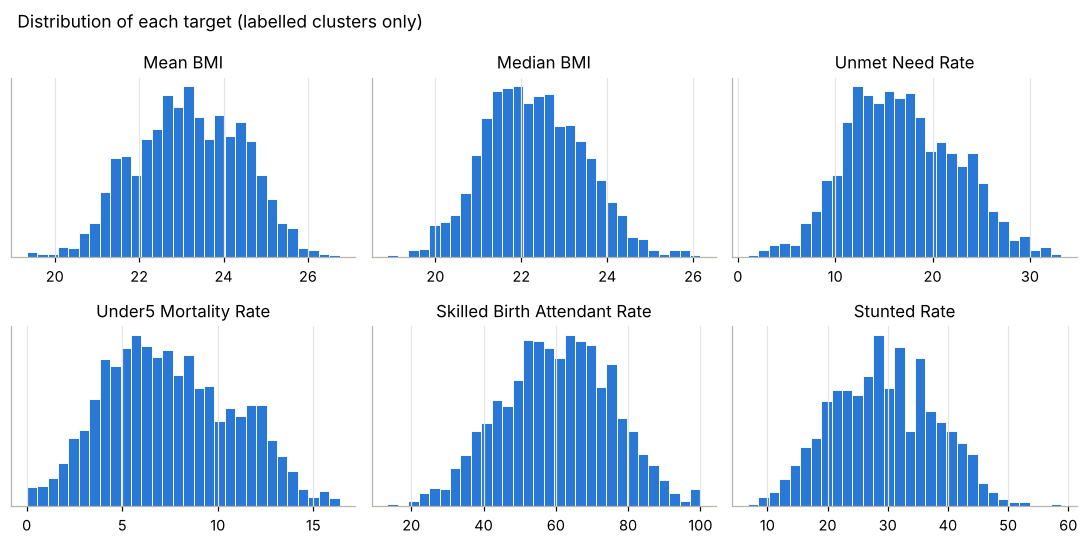

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(10, 5))
for ax, t in zip(axes.ravel(), config.TARGET_COLUMNS):
    ax.hist(labels[t].dropna(), bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
    ax.set_title(t.replace("_", " "))
    ax.set_yticks([])
fig.suptitle("Distribution of each target (labelled clusters only)", x=0.02, ha="left")
fig.tight_layout()

## 4. Step 2: Screen features without loading 8 GB into RAM

**Problem.** `gee_features.csv` is ~8.15 GB. As float64 in pandas that becomes even larger, more than a Kaggle notebook's RAM.

**Solution: two passes, neither of which loads the whole file.**
1. Use the **10% sample file** to decide *which columns are worth keeping*. We stream it in chunks and accumulate count / sum / sum-of-squares per column. That gives the missing rate and variance without holding the data.
2. Drop identifiers and text (`DHSID`, `DHSYEAR`, `ADM1NAME`…), columns that are **>98% missing**, and **constant** columns. Rank the rest by `log1p(variance) × (1 − missing_rate)` and keep the top **250**. That is the "250-feature superset".

The screen **never looks at the labels**, so it cannot leak target information.

> **Know the quirk.** Variance depends on units, so features with big raw numbers rank high. Coordinates (`LATNUM`/`LONGNUM`, in degrees) top the list below. Keeping coordinates is a defensible choice, because location is genuinely informative. But a unit-free score (for example the coefficient of variation, or ranking within each feature family) would be fairer. Try it in Exercise 8.

In [5]:
from src.real_data import candidate_columns, score_features, screen_features

cands = candidate_columns(DATA_DIR)
scores = score_features(DATA_DIR, cands)
screened = screen_features(DATA_DIR, config.N_SCREEN_FEATURES)
print(f"numeric candidate columns : {len(cands)}")
print(f"pass missing/constant test: {len(scores)}  (dropped {len(cands) - len(scores)})")
print(f"kept for the superset     : {len(screened)}")
scores.head(8)

numeric candidate columns : 602
pass missing/constant test: 592  (dropped 10)
kept for the superset     : 250


,missing_rate,variance,rank_score
LONGNUM,0.000000,2056.110154,7.629057
LATNUM,0.000000,151.259182,5.025584
worldpop_p25_085,0.036364,2.273173,1.142641
lst_day_median_018,0.018182,2.172130,1.133414
landcover_urban_min_174,0.027273,2.097679,1.099817
ghsl_built_std_151,0.027273,2.090427,1.097537
worldpop_mean_341,0.013636,2.012556,1.087751
landcover_crop_p25_205,0.022727,2.022832,1.081053


## 5. Step 3: Join features to labels on `DHSID`

Now stream the **full** file in 10,000-row chunks. Read only `DHSID` and the 250 screened columns, and keep only rows whose `DHSID` is in the labels or the submission. Memory stays bounded by what we actually need.

Real-data quirks this step handles (the synthetic data copies each of them):
* **Duplicate DHSID in the GEE file** (one conflicting Bolivia row in the real data). Keep the first, so every cluster has exactly one feature vector.
* **Submission clusters with no GEE row** (**25** in the real data). We *left*-join so the submission keeps every row, and fill those rows later with the training mean. This is an explicit, documented fallback, **not** a feature-based prediction.
* `validate="one_to_one"` in `merge` makes pandas raise an error if the join would silently duplicate rows. Use it on every join.
* Features are cast to **float32** to halve memory.

In [6]:
from src.real_data import build_train_test

train, test, labels, submission, n_missing = build_train_test(DATA_DIR, screened)
print(f"train (labelled + features): {train.shape}")
print(f"test  (submission rows)    : {test.shape}   rows with no GEE features: {n_missing}")
print(f"memory of train table      : {train.memory_usage(deep=True).sum() / 1e6:.1f} MB")

train (labelled + features): (1500, 257)
test  (submission rows)    : (400, 251)   rows with no GEE features: 5
memory of train table      : 1.7 MB


## 6. Step 4: NN + Kernel SHAP feature selection (250 → 100)

**Why select at all?** 250 correlated satellite statistics (mean, median and p75 of the same layer are near-duplicates) make tuning slower and add noise. We want the ~100 that carry environmental and population context.

**How:**
1. **Split first.** Selection runs on the **training split only**. If the validation rows helped choose features, the validation score would be optimistic (leakage).
2. For each target: median-impute and standardise (neural nets need complete, scaled inputs), then fit a small **MLP (64→32)**.
3. **Kernel SHAP** on the MLP gives the mean |SHAP| per feature, i.e. how much each feature moves the prediction.
4. **Normalise per target** (divide by that target's max) so the six targets count equally, **average**, and keep the top 100.

**Why a NN and not XGBoost for ranking?** A different model family gives a second view of what matters, instead of rewarding the splits the final trees would make anyway.

> **A bug we found and fixed: the Kernel SHAP sample budget.** Kernel SHAP estimates each row's SHAP values by solving a weighted least-squares problem over `nsamples` random feature coalitions. The first version used **50 samples for 250 features**: fewer equations than unknowns. Most rows looked fine, but occasionally one row came back with values around **±10^15** that cancel each other out. Max-normalisation then erased every other feature's signal for that target. Now `nsamples = 2 × n_features + extra` (SHAP's own default rule). This costs only seconds per target. We also check **additivity** (SHAP values must sum to *prediction − expected value*) and warn if it fails.
>
> The ranking still explains only a sample of rows (12 in fast mode, 200 in full mode), so treat it as a good *approximation*. Alternatives include `shap.GradientExplainer` for neural nets, or permutation importance (Section 13).

In [7]:
from sklearn.model_selection import train_test_split
from src.shap_selection import select_top_features

X, y = train[screened], train[config.TARGET_COLUMNS]
tr_idx, va_idx = train_test_split(np.arange(len(train)), test_size=config.VALIDATION_FRACTION,
                                  random_state=config.RANDOM_STATE)
Xtr, Xva, ytr, yva = X.iloc[tr_idx], X.iloc[va_idx], y.iloc[tr_idx], y.iloc[va_idx]

top, rankings = select_top_features(Xtr, ytr, config.TARGET_COLUMNS, fast=FAST, return_rankings=True)
print(f"selected {len(top)} of {len(screened)} features")
rankings.head(10).round(3)

      SHAP ranking: Mean_BMI


      SHAP ranking: Median_BMI


      SHAP ranking: Unmet_Need_Rate


      SHAP ranking: Under5_Mortality_Rate


      SHAP ranking: Skilled_Birth_Attendant_Rate


      SHAP ranking: Stunted_Rate


selected 100 of 250 features


,Mean_BMI,Median_BMI,Unmet_Need_Rate,Under5_Mortality_Rate,Skilled_Birth_Attendant_Rate,Stunted_Rate,combined
lst_night_min_387,0.034,0.007,0.115,0.234,0.712,0.213,0.475
dist_road_p25_312,0.000,0.000,0.353,0.582,0.000,0.165,0.436
lst_day_min_274,0.000,0.051,0.189,0.198,0.688,0.033,0.373
pdsi_mean_347,0.045,0.073,0.078,0.132,0.067,0.145,0.311
lst_night_mean_115,0.077,0.020,0.000,0.000,0.075,0.197,0.270
surface_water_std_492,0.086,0.000,0.109,0.000,0.000,0.124,0.255
evi_std_042,0.098,0.095,0.034,0.000,0.000,0.000,0.243
landcover_urban_max_414,0.050,0.035,0.028,0.000,0.000,0.188,0.233
landcover_crop_p25_093,0.000,0.190,0.016,0.004,0.000,0.084,0.227
worldpop_median_581,0.076,0.000,0.147,0.023,0.000,0.038,0.211


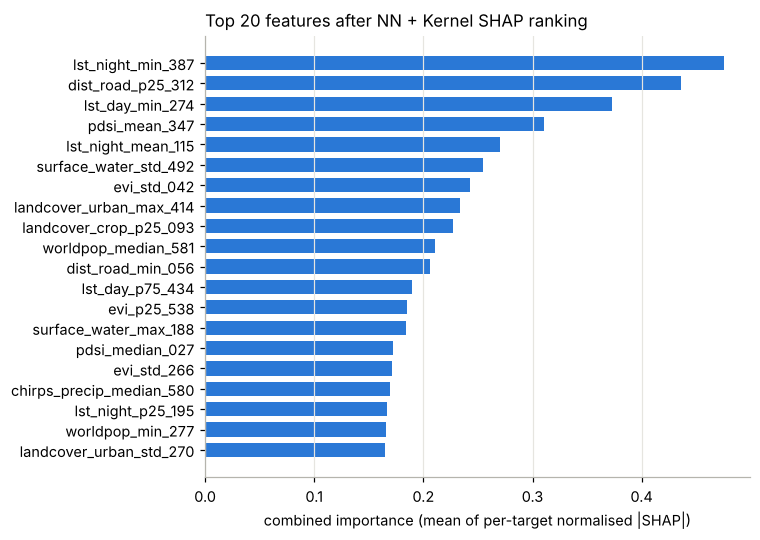

In [8]:
top20 = rankings["combined"].head(20)[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top20.index, top20.values, color=BLUE, height=0.7)
ax.set_xlabel("combined importance (mean of per-target normalised |SHAP|)")
ax.set_title("Top 20 features after NN + Kernel SHAP ranking", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()

In the synthetic data only 15 features carry signal, so expect noisy rankings past the top few. With real data, check whether the top features make domain sense. Night lights, population density, built-up area and travel time to cities are known proxies for wealth and service access, so they should rank high for skilled birth attendance and stunting.

## 7. Step 5: XGBoost with Huber loss, and the `base_score` fix

### 7.1 Why Huber loss?
Cluster-level rates come from small samples (~20–30 households), so some labels are very noisy. A cluster with 3 eligible children can show a 100% stunting rate. Squared error grows with the *square* of the residual, so such clusters dominate training. **Pseudo-Huber** loss, $\delta^2\left(\sqrt{1+(r/\delta)^2}-1\right)$, is quadratic for small residuals and roughly linear beyond $\delta$ (`huber_slope`). We tune $\delta$ per target.

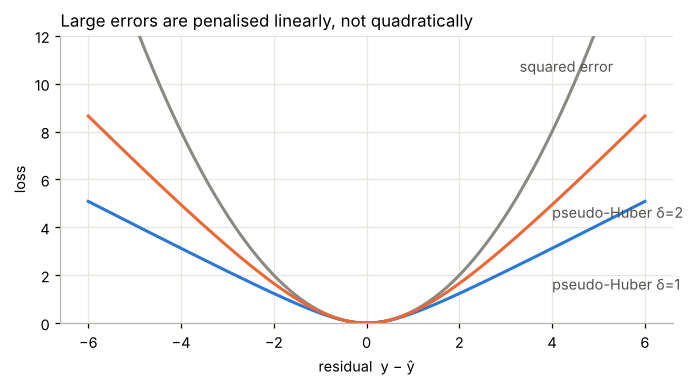

In [9]:
r = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(r, 0.5 * r**2, color=GREY, lw=2)
for d, c in [(1.0, BLUE), (2.0, ORANGE)]:
    ax.plot(r, d**2 * (np.sqrt(1 + (r / d) ** 2) - 1), color=c, lw=2)
ax.set_ylim(0, 12); ax.set_xlabel("residual  y − ŷ"); ax.set_ylabel("loss")
ax.text(3.3, 10.5, "squared error", color="#52514e")
ax.text(4.0, 4.4, "pseudo-Huber δ=2", color="#52514e")
ax.text(4.0, 1.4, "pseudo-Huber δ=1", color="#52514e")
ax.set_title("Large errors are penalised linearly, not quadratically", loc="left")
fig.tight_layout()

### 7.2 The bug: `base_score` divergence

Boosting starts every prediction at a constant, `base_score`, and adds trees on top. XGBoost takes **Newton steps**: leaf value ≈ −(sum of gradients)/(sum of hessians). For pseudo-Huber:

* gradient = $r / \sqrt{1+(r/\delta)^2}$, which is capped at about ±δ
* hessian = $(1+(r/\delta)^2)^{-3/2}$, which **shrinks towards 0** as |r| grows

If the starting point is far from the targets (say BMI ≈ 23 but the start is 0.5, or some poorly auto-estimated value), *every* residual is large. Gradients saturate, hessians nearly vanish, and gradient/hessian becomes a huge step. Training overshoots and can **diverge to a constant, wildly wrong prediction**.

**The fix (one line in `src/model.py`):** `base_score = y.mean()` for each target. Residuals then start small, in the region where the loss behaves well. Watch it happen:

In [10]:
from xgboost import XGBRegressor
from src.evaluate import rmse

t = "Mean_BMI"
ok_tr, ok_va = ytr[t].notna(), yva[t].notna()
Xa, ya, Xb, yb = Xtr.loc[ok_tr, top], ytr.loc[ok_tr, t], Xva.loc[ok_va, top], yva.loc[ok_va, t]

common = dict(objective="reg:pseudohubererror", n_estimators=300, learning_rate=0.05,
              max_depth=4, huber_slope=1.0, tree_method="hist", random_state=42)
runs = {"XGBoost default start": {}, "base_score = 0.5": {"base_score": 0.5},
        "base_score = target mean (fix)": {"base_score": float(ya.mean())}}
curves, rows = {}, []
for name, extra in runs.items():
    m = XGBRegressor(**common, **extra, eval_metric="rmse")
    m.fit(Xa, ya, eval_set=[(Xb, yb)], verbose=False)
    curves[name] = m.evals_result()["validation_0"]["rmse"]
    rows.append({"setting": name, "validation RMSE": rmse(yb, m.predict(Xb)),
                 "mean prediction": float(m.predict(Xb).mean()), "true mean": float(yb.mean())})
pd.DataFrame(rows).round(3)

,setting,validation RMSE,mean prediction,true mean
0,XGBoost default start,23.310,46.459,23.182
1,base_score = 0.5,23.335,-0.120,23.182
2,base_score = target mean (fix),1.111,23.211,23.182


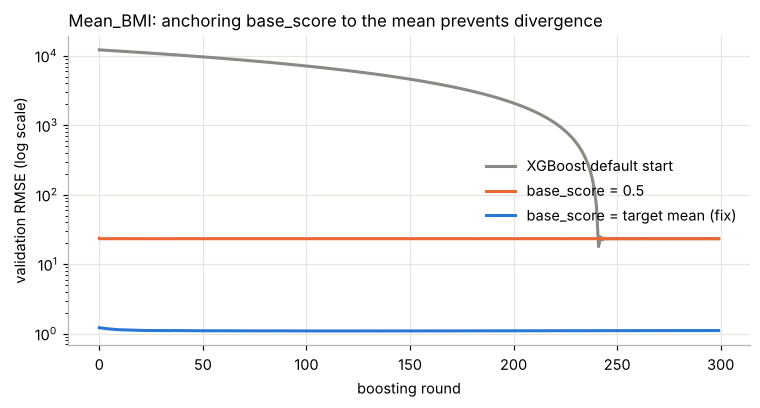

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, c), col in zip(curves.items(), [GREY, ORANGE, BLUE]):
    ax.plot(c, color=col, lw=2, label=name)
ax.legend(loc="center right", frameon=False)
ax.set_yscale("log"); ax.set_xlabel("boosting round"); ax.set_ylabel("validation RMSE (log scale)")
ax.set_title(f"{t}: anchoring base_score to the mean prevents divergence", loc="left")
fig.tight_layout()

**Reading the chart.** Grey: XGBoost's own automatic `base_score` estimate lands far from the data (around 10⁴ here). Boosting spends hundreds of rounds walking back, then stalls at a near-constant prediction. Orange: starting at 0.5, the saturated gradients and vanishing hessians mean the model never makes useful progress. Blue: anchored at the mean, the model learns from the first round. Same data, same trees, same loss. Only the starting point differs.

### 7.3 Tuning: one model per target
`RandomizedSearchCV` tries 25 random combinations (3 in fast mode) of `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `huber_slope` and `min_child_weight`, each scored by 5-fold CV RMSE. The best combination is refitted on the full training split. Each target gets its own search, because their noise levels differ.

XGBoost handles the **missing feature values** natively: at each split it learns which side missing values should go. So unlike the NN step, no imputation is needed.

In [12]:
from src import model

fitted = model.fit_all_targets(Xtr[top], ytr, config.TARGET_COLUMNS, fast=FAST)
pd.DataFrame({t: v["best_params"] for t, v in fitted.items()}).T

      Mean_BMI                       rows=1,008


      Median_BMI                     rows=1,018


      Unmet_Need_Rate                rows=1,065


      Under5_Mortality_Rate          rows=1,143


      Skilled_Birth_Attendant_Rate   rows=1,151


      Stunted_Rate                   rows=845


,subsample,min_child_weight,max_depth,learning_rate,huber_slope,colsample_bytree
Mean_BMI,1.0,3.0,3.0,0.03,1.5,0.8
Median_BMI,1.0,3.0,3.0,0.03,1.5,0.8
Unmet_Need_Rate,1.0,3.0,3.0,0.03,1.5,0.8
Under5_Mortality_Rate,0.8,5.0,6.0,0.01,2.0,0.8
Skilled_Birth_Attendant_Rate,1.0,3.0,3.0,0.03,1.5,0.8
Stunted_Rate,1.0,3.0,3.0,0.03,1.5,0.8


## 8. Step 6: Evaluate against a baseline, and the question of spatial leakage

An RMSE value means little on its own. Always compare it with the **baseline of predicting the training mean**. If the model does not beat that, the features carry no usable signal.

In [13]:
from src import evaluate

metrics = evaluate.evaluate_all(fitted, Xva[top], yva, y_train=ytr)
res = pd.DataFrame({"model RMSE": metrics["per_target_rmse"],
                    "baseline RMSE": metrics["baseline_per_target_rmse"]})
res["improvement %"] = 100 * (1 - res["model RMSE"] / res["baseline RMSE"])
print(f"MEAN RMSE across 6 targets: {metrics['mean_rmse']:.3f}   (baseline {metrics['baseline_mean_rmse']:.3f})")
res.round(3)

MEAN RMSE across 6 targets: 4.879   (baseline 5.873)


,model RMSE,baseline RMSE,improvement %
Mean_BMI,1.073,1.234,12.990
Median_BMI,1.020,1.147,11.029
Unmet_Need_Rate,5.052,5.975,15.449
Under5_Mortality_Rate,2.640,3.277,19.441
Skilled_Birth_Attendant_Rate,12.682,15.172,16.409
Stunted_Rate,6.806,8.433,19.297


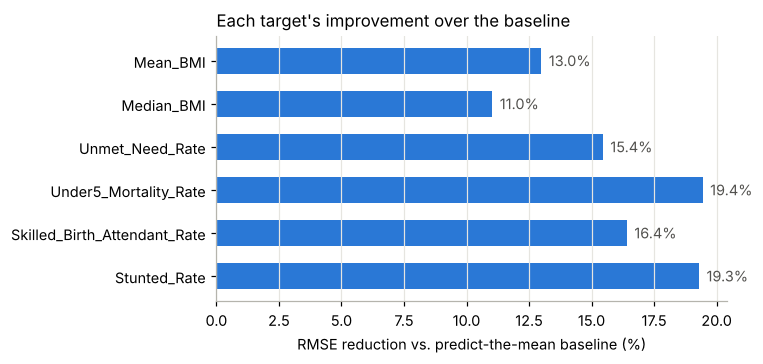

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.4))
imp = res["improvement %"].iloc[::-1]
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
for i, v in enumerate(imp.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", color="#52514e")
ax.set_xlabel("RMSE reduction vs. predict-the-mean baseline (%)")
ax.set_title("Each target's improvement over the baseline", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()

### Spatial leakage: is a random split too optimistic?
Clusters in the same country share climate, policy and survey timing, so nearby clusters have similar features *and* similar labels. With a random split, the validation set holds near-copies of training clusters. That measures **interpolation within known countries**. If the goal is **predicting in places with no survey**, hold out whole countries instead (`--split country`, using the first 2 characters of `DHSID`). Compare the two:

In [15]:
from src.pipeline import split_indices

rows = []
for how in ["random", "country"]:
    a, b = split_indices(train, how)
    for t in ["Skilled_Birth_Attendant_Rate", "Stunted_Rate"]:
        ya_, yb_ = y.iloc[a][t], y.iloc[b][t]
        ka, kb = ya_.notna(), yb_.notna()
        m = model.make_model(ya_[ka], fast=True, **fitted[t]["best_params"])
        m.fit(X.iloc[a][top][ka], ya_[ka])
        rows.append({"split": how, "target": t, "RMSE": rmse(yb_[kb], m.predict(X.iloc[b][top][kb]))})
pd.DataFrame(rows).pivot(index="target", columns="split", values="RMSE").round(3)

split,country,random
target,,
Skilled_Birth_Attendant_Rate,13.675,12.682
Stunted_Rate,7.490,6.806


On real data, expect the country split to give a **higher** RMSE. Report which split a number comes from. The project's headline numbers use the **random** split.

## 9. Step 7: Final refit and the submission file

Validation told us how good the approach is. For the final predictions we **refit on all labelled rows**, using the tuned hyper-parameters (`fixed_params`, so no second search is needed). More data gives better final models. Rows with no GEE features get the training mean.

In [16]:
best = {t: fitted[t]["best_params"] for t in config.TARGET_COLUMNS}
final = model.fit_all_targets(X[top], y, config.TARGET_COLUMNS, fast=FAST, fixed_params=best)

pred = submission.copy()
no_feat = test[top].isna().all(axis=1).to_numpy()
for t in config.TARGET_COLUMNS:
    pred[t] = final[t]["model"].predict(test[top])
    pred.loc[no_feat, t] = float(y[t].mean())
print(f"{len(pred)} rows, {no_feat.sum()} filled with the training-mean fallback")
pred.iloc[3:9]   # rows 3-4 are fallback rows (no GEE features), 5+ are model predictions

      Mean_BMI                       rows=1,265


      Median_BMI                     rows=1,271


      Unmet_Need_Rate                rows=1,328


      Under5_Mortality_Rate          rows=1,431


      Skilled_Birth_Attendant_Rate   rows=1,437


      Stunted_Rate                   rows=1,059


400 rows, 5 filled with the training-mean fallback


,DHSID,Mean_BMI,Median_BMI,Unmet_Need_Rate,Under5_Mortality_Rate,Skilled_Birth_Attendant_Rate,Stunted_Rate
3,NG201800001503,23.173208,22.298401,16.837074,7.483727,60.281982,29.341547
4,IA201600001504,23.173208,22.298401,16.837074,7.483727,60.281982,29.341547
5,PE201800001505,23.254410,22.844221,16.638264,7.644902,53.520023,32.257721
6,PE201400001506,24.246067,21.791273,13.727573,8.105788,62.452557,28.052341
7,ET202100001507,22.991173,22.744141,18.166872,6.546163,70.219261,33.609383
8,TZ202100001508,23.302368,22.178364,19.743654,7.971700,65.111374,28.377892


## 10. Running the real thing on Kaggle

The whole notebook above is one command, `src/pipeline.py`, which also saves its outputs to `reports/`.

```bash
# 0) local smoke test, no data needed (~1 min)
python -m src.pipeline --synthetic --fast

# 1) Kaggle, FIRST run: small budget, checks the whole real-data path end to end
python -m src.pipeline --data-dir /kaggle/input/<competition-folder> --fast

# 2) Kaggle, full run: 25-iteration search, 5-fold CV, 600 trees, bigger SHAP budget
python -m src.pipeline --data-dir /kaggle/input/<competition-folder>

# optional: honest "unseen country" estimate
python -m src.pipeline --data-dir /kaggle/input/<competition-folder> --split country
```

**Getting the code into Kaggle:** push the repo to GitHub, then in a Kaggle notebook run `!git clone https://github.com/<you>/lmic-health-pipeline.git && cd lmic-health-pipeline` (internet must be on in notebook settings). Or upload the repo zip as a Kaggle *Dataset* and copy it to `/kaggle/working`.

**Outputs (`reports/`):**
| file | contents |
|---|---|
| `metrics.json` | per-target RMSE, **mean RMSE**, baseline RMSE, best params, selected features, row counts, runtime |
| `submission.csv` | `DHSID` + 6 predictions, same row order as the sample submission |
| `shap_rankings.csv` | per-target and combined SHAP importances for all 250 screened features |
| `models/xgb_<target>.json` | the six final models (`XGBRegressor().load_model(path)` to reuse) |

**Your real RMSE will differ from earlier runs.** It depends on the split, the search iterations, the SHAP budget and library versions. Quote the number from *your* `metrics.json`, and say which split and settings produced it.

## 11. Problems we hit and how we fixed them

| # | Problem | Symptom | Fix (where) |
|---|---|---|---|
| 1 | **`base_score` divergence** with `reg:pseudohubererror` | predictions collapse to a constant far from the targets; RMSE in the tens or thousands | `base_score = y.mean()` per target (`model.make_model`) |
| 2 | **8.15 GB GEE file** does not fit in RAM | kernel crash / OOM | screen columns on the 10% file, then stream the full file in chunks with `usecols` and an ID filter; float32 (`real_data.py`) |
| 3 | **Duplicate `DHSID`s** (labels, and one conflicting Bolivia GEE row) | merges silently duplicate rows | `drop_duplicates(keep="first")` + `merge(validate="one_to_one")` |
| 4 | **25 submission IDs have no GEE row** | NaN predictions / wrong row count | left-join on the submission; fill with the training mean and report the count |
| 5 | **Different labels missing per target** | dropping any-NaN rows throws away data | fit each target on its own labelled rows (`fit_all_targets`) |
| 6 | **Leakage risk in feature selection** | optimistic validation RMSE | SHAP ranking only on the training split; the screen does not use labels |
| 7 | **Kernel SHAP under-sampled** (50 coalition samples for 250 features) | occasional importances around 1e15 for one target; ranking dominated by 1–2 junk features | `nsamples = 2·n_features + extra` and an additivity check (`shap_selection.py`) |
| 8 | **Kernel SHAP is slow** | very long runs with large row counts | NN/SHAP on ≤5,000 rows per target, small background/explain sets; `--fast` mode for the first run |
| 9 | **Identifiers as features** (`DHSCLUST`, `DHSYEAR`, admin codes) | the model memorises IDs | `DROP_FEATURE_COLUMNS` in `config.py` |
| 10 | **Wasted Kaggle hours** on a full run that fails late | error after a long run | `--fast` first: same code path, tiny budget |

## 12. Mapping the CV bullets to the code, and interview prep

| CV claim | Where it lives | What to be ready to explain |
|---|---|---|
| Predict maternal & child health outcomes in LMICs using geospatial data | whole repo | why satellites help: surveys are sparse in space and time |
| Geospatial ML pipeline, **8 GB GEE imagery**, **DHS**/OSM data, **6 indicators**, **cluster level** | `real_data.py`, `targets.py`, `geo_features.py` | chunked streaming of the 8.15 GB file; DHSID joins; what a cluster is; OSM buffer features |
| **100 features from a 250-feature superset** with **NN-based SHAP** | `config.N_SCREEN_FEATURES=250`, `N_SHAP_FEATURES=100`, `shap_selection.py` | the two stages; per-target normalisation; why on the train split only; Kernel SHAP limits |
| **Per-target XGBoost**, **Huber loss**, **fixed base_score divergence** | `model.py` | Newton step, vanishing hessian, the demo in Section 7.2 |
| **Mean RMSE across all 6 targets** | `evaluate.py`, `reports/metrics.json` | it is the mean of 6 per-target RMSEs in different units; compare with the baseline |

**Update your RMSE number.** This version trains differently, so replace the old figure with the `mean_rmse` from your new `reports/metrics.json`. A suggested wording:

> • Trained & tuned per-target XGBoost regressors with pseudo-Huber loss, fixing a base_score divergence; achieved **⟨your mean_rmse⟩** mean RMSE across all 6 targets (**⟨x⟩%** below a mean-prediction baseline)

On OSM: the main pipeline's features come from the GEE file. If you list OSM on your CV, be ready to show `geo_features.py` and explain how its features would be merged in.

**Likely interview questions:**
1. *Why one model per target instead of multi-output?* Targets have different scales, noise and missing-label patterns, and each gets its own `huber_slope` and depth. A multi-output model would also force us to drop rows missing any target.
2. *Why Huber and not plain MSE?* Small-sample clusters create outlier labels. Huber reduces their pull while staying smooth enough for Newton boosting.
3. *Explain the base_score bug.* (Section 7.2.) Pseudo-Huber hessian → 0 for large residuals, so Newton steps blow up when the start is far from the data. Starting at the mean fixes it.
4. *Why SHAP for selection and not XGBoost gain?* Gain is biased toward high-cardinality / frequently split features. SHAP is consistent and model-agnostic. Using a NN gives a ranking independent of the final model.
5. *How do you know the model is useful?* It beats the predict-the-mean baseline on every target. With a country-held-out split, it shows how far it transfers.
6. *What would you do next?* Spatial CV, LightGBM/CatBoost ensemble, more SHAP budget, target transforms for bounded rates, and uncertainty intervals (quantile loss).

## 13. Exercises and next steps

1. **Change the superset size.** Run with `--n-screen 500` and compare the validation RMSE with 250.
2. **Change the selected count.** Set `config.N_SHAP_FEATURES = 50` or `150`. Is 100 a good trade-off?
3. **Swap the explainer.** Replace Kernel SHAP with `sklearn.inspection.permutation_importance` on the MLP and compare the top 20.
4. **Country split.** Run the full pipeline with `--split country`. How much worse is it, and for which targets?
5. **Add OSM features.** Download an OSM extract for one country, build features with `geo_features.build_osm_features`, merge on `DHSID`, and check whether they enter the top 100.
6. **Bounded targets.** Rates live in [0, 100]. Try clipping predictions, or train on a logit transform, and compare RMSE.
7. **Ensembling.** Average XGBoost with LightGBM per target.
8. **Fairer screening.** Replace `log1p(variance)` in `real_data.score_features` with a unit-free score and see whether the selected 100 change.

Run the tests after every change:
```bash
python -m pytest -q
```